In [7]:

import os
import time
import threading
import psutil
import pandas as pd

print("Pandas version:", pd.__version__)
print("Process ID:", os.getpid())
print("Libraries imported successfully.")


Pandas version: 2.3.3
Process ID: 48
Libraries imported successfully.


In [8]:

import os

print("Contents of /kaggle/input:")

if os.path.exists("/kaggle/input"):
    print(os.listdir("/kaggle/input"))
else:
    print("Input directory does not exist")


Contents of /kaggle/input:
['datasets']


In [9]:

import os

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)
            size_gb = os.path.getsize(path) / (1024**3)
            print(f"{file} | {size_gb:.2f} GB")


Wincons.csv | 0.00 GB
CardMasterListSeason18_12082020.csv | 0.00 GB
battlesStaging_12282020_WL_tagged.csv | 1.04 GB
BattlesStaging_12302020_WL_tagged.csv | 1.32 GB
BattlesStaging_12312020_WL_tagged.csv | 1.44 GB
BattlesStaging_01042021_WL_tagged.csv | 0.61 GB
battlesStaging_12072020_to_12262020_WL_tagged.csv | 9.20 GB
BattlesStaging_01022021_WL_tagged.csv | 1.61 GB
battlesStaging_12272020_WL_tagged.csv | 1.04 GB
BattlesStaging_01012021_WL_tagged.csv | 1.55 GB
BattlesStaging_12292020_WL_tagged.csv | 1.28 GB
BattlesStaging_01032021_WL_tagged.csv | 1.70 GB


In [10]:

import os

file_path = None

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    for file in files:
        if file == "battlesStaging_12072020_to_12262020_WL_tagged.csv":
            file_path = os.path.join(root, file)
            break
    if file_path is not None:
        break

if file_path:
    print("Dataset file found successfully!")
    print("File path:", file_path)
    print(f"File size: {os.path.getsize(file_path) / (1024**3):.2f} GB")
else:
    print("File not found. Please check the dataset attachment.")


Dataset file found successfully!
File path: /kaggle/input/datasets/bwandowando/clash-royale-season-18-dec-0320-dataset/BattlesStaging_12072020_to_12262020_WL_tagged/battlesStaging_12072020_to_12262020_WL_tagged.csv
File size: 9.20 GB


In [11]:

import pandas as pd

# Read only the column names, not the entire 9.20 GB file
columns = pd.read_csv(file_path, nrows=0).columns.tolist()

print("Number of columns:", len(columns))
print("\nIs target column available?",
      "winner.trophyChange" in columns)

print("\nFirst 15 columns:")
print(columns[:15])


Number of columns: 74

Is target column available? True

First 15 columns:
['Unnamed: 0', 'battleTime', 'arena.id', 'gameMode.id', 'average.startingTrophies', 'winner.tag', 'winner.startingTrophies', 'winner.trophyChange', 'winner.crowns', 'winner.kingTowerHitPoints', 'winner.princessTowersHitPoints', 'winner.clan.tag', 'winner.clan.badgeId', 'loser.tag', 'loser.startingTrophies']


In [12]:


import os
import time
import pandas as pd
import psutil

print("Pandas version:", pd.__version__)
print("Libraries imported successfully.")


Pandas version: 2.3.3
Libraries imported successfully.


In [15]:

dataset_root = "/kaggle/input/datasets"

target_file = "battlesStaging_12072020_to_12262020_WL_tagged.csv"
file_path = None

for root, dirs, files in os.walk(dataset_root):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        break

if file_path is not None:
    file_size_gb = os.path.getsize(file_path) / (1024 ** 3)

    print("File found successfully!")
    print("Path:", file_path)
    print(f"File size: {file_size_gb:.2f} GB")
else:
    print("File not found. Check that the Kaggle dataset is attached.")


File found successfully!
Path: /kaggle/input/datasets/bwandowando/clash-royale-season-18-dec-0320-dataset/BattlesStaging_12072020_to_12262020_WL_tagged/battlesStaging_12072020_to_12262020_WL_tagged.csv
File size: 9.20 GB


In [ ]:

if file_path is None:
    raise FileNotFoundError("Please run the previous cell and locate the dataset.")

process = psutil.Process(os.getpid())

ram_before = process.memory_info().rss / (1024 ** 3)
start_time = time.time()

print(f"RAM before loading: {ram_before:.2f} GB")

df = pd.read_csv(file_path)

execution_time = time.time() - start_time
ram_after = process.memory_info().rss / (1024 ** 3)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print(f"Execution time: {execution_time:.2f} seconds")
print(f"RAM after loading: {ram_after:.2f} GB")

print("\nFirst 5 rows:")
display(df.head())

print("\nMean of winner.trophyChange:")
print(df["winner.trophyChange"].mean())


RAM before loading: 0.26 GB


In [ ]:

%pip install "dask[dataframe]"


In [3]:
import os

file_path = None

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    for file in files:
        if file == "battlesStaging_12072020_to_12262020_WL_tagged.csv":
            file_path = os.path.join(root, file)
            break
    if file_path is not None:
        break

if file_path:
    print("Dataset file found successfully!")
    print("File path:", file_path)
    print(f"File size: {os.path.getsize(file_path) / (1024**3):.2f} GB")
else:
    print("File not found. Please check the dataset attachment.")

Dataset file found successfully!
File path: /kaggle/input/datasets/bwandowando/clash-royale-season-18-dec-0320-dataset/BattlesStaging_12072020_to_12262020_WL_tagged/battlesStaging_12072020_to_12262020_WL_tagged.csv
File size: 9.20 GB


In [4]:
dataset_root = "/kaggle/input/datasets"

target_file = "battlesStaging_12072020_to_12262020_WL_tagged.csv"
file_path = None

for root, dirs, files in os.walk(dataset_root):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        break

if file_path is not None:
    file_size_gb = os.path.getsize(file_path) / (1024 ** 3)

    print("File found successfully!")
    print("Path:", file_path)
    print(f"File size: {file_size_gb:.2f} GB")
else:
    print("File not found. Check that the Kaggle dataset is attached.")


File found successfully!
Path: /kaggle/input/datasets/bwandowando/clash-royale-season-18-dec-0320-dataset/BattlesStaging_12072020_to_12262020_WL_tagged/battlesStaging_12072020_to_12262020_WL_tagged.csv
File size: 9.20 GB


In [5]:

import os
import time
import threading
import psutil
import pandas as pd

process = psutil.Process(os.getpid())

ram_before = process.memory_info().rss / (1024 ** 3)
peak_ram = [ram_before]
stop_monitor = threading.Event()

def monitor_ram():
    while not stop_monitor.is_set():
        try:
            current_ram = process.memory_info().rss / (1024 ** 3)
            peak_ram[0] = max(peak_ram[0], current_ram)
        except psutil.Error:
            pass

        stop_monitor.wait(0.05)

monitor_thread = threading.Thread(
    target=monitor_ram,
    daemon=True
)
monitor_thread.start()

start_time = time.time()

total_sum = 0.0
total_count = 0
num_chunks = 0

try:
    for chunk in pd.read_csv(
        file_path,
        usecols=["winner.trophyChange"],
        chunksize=100_000
    ):
        values = pd.to_numeric(
            chunk["winner.trophyChange"],
            errors="coerce"
        )

        total_sum += values.sum()
        total_count += values.count()
        num_chunks += 1

finally:
    stop_monitor.set()
    monitor_thread.join()

execution_time = time.time() - start_time
ram_after = process.memory_info().rss / (1024 ** 3)

print("Number of chunks:", num_chunks)
print(f"Global mean: {total_sum / total_count:.4f}")
print(f"Execution time: {execution_time:.2f} seconds")
print(f"RAM before: {ram_before:.3f} GB")
print(f"RAM after: {ram_after:.3f} GB")
print(f"Peak RAM observed: {peak_ram[0]:.3f} GB")
print(
    f"Peak increase over initial RAM: "
    f"{max(0, peak_ram[0] - ram_before):.3f} GB"
)


Number of chunks: 168
Global mean: 29.4854
Execution time: 163.31 seconds
RAM before: 0.162 GB
RAM after: 0.168 GB
Peak RAM observed: 0.182 GB
Peak increase over initial RAM: 0.020 GB


In [10]:

import os
import time
import threading
import psutil
import dask
import dask.dataframe as dd

# Check the file path
assert os.path.exists(file_path), "CSV file not found!"

# Monitor the current Python process
process = psutil.Process(os.getpid())

ram_before = process.memory_info().rss / (1024 ** 3)
peak_ram = [ram_before]
stop_monitor = threading.Event()

def monitor_ram():
    while not stop_monitor.is_set():
        try:
            current_ram = process.memory_info().rss / (1024 ** 3)
            peak_ram[0] = max(peak_ram[0], current_ram)
        except psutil.Error:
            pass

        stop_monitor.wait(0.05)

monitor_thread = threading.Thread(
    target=monitor_ram,
    daemon=True
)
monitor_thread.start()

start_time = time.time()

try:
    # Create the Dask DataFrame
    ddf = dd.read_csv(
        file_path,
        usecols=["winner.trophyChange"],
        blocksize="64 MiB"
    )

    print("Number of partitions:", ddf.npartitions)

    # Calculate global mean using Dask
    global_mean = ddf["winner.trophyChange"].mean().compute()

finally:
    execution_time = time.time() - start_time
    stop_monitor.set()
    monitor_thread.join()

ram_after = process.memory_info().rss / (1024 ** 3)

print("\n--- Dask Results ---")
print(f"Global mean: {global_mean:.4f}")
print(f"Execution time: {execution_time:.2f} seconds")
print(f"RAM before: {ram_before:.3f} GB")
print(f"RAM after: {ram_after:.3f} GB")
print(f"Peak RAM observed: {peak_ram[0]:.3f} GB")
print(
    f"Peak increase over initial RAM: "
    f"{max(0, peak_ram[0] - ram_before):.3f} GB"
)


Number of partitions: 147

--- Dask Results ---
Global mean: 29.4854
Execution time: 39.54 seconds
RAM before: 0.254 GB
RAM after: 0.256 GB
Peak RAM observed: 0.823 GB
Peak increase over initial RAM: 0.570 GB


Performance Comparison


,Method,Execution Time (seconds),RAM Before (GB),RAM After (GB),Peak RAM (GB),Peak Increase (GB),Global Mean,Partitions / Chunks
0,Pandas Chunking,261.22,0.162,0.169,0.182,0.020,29.4854,168
1,Dask DataFrame,56.87,0.228,0.259,0.822,0.593,29.4854,147



Dask speedup: 4.59x
Execution time reduction: 78.23%


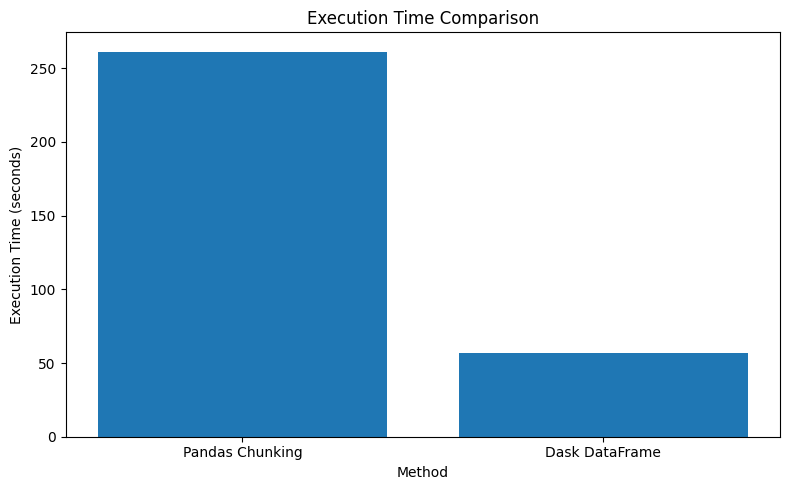

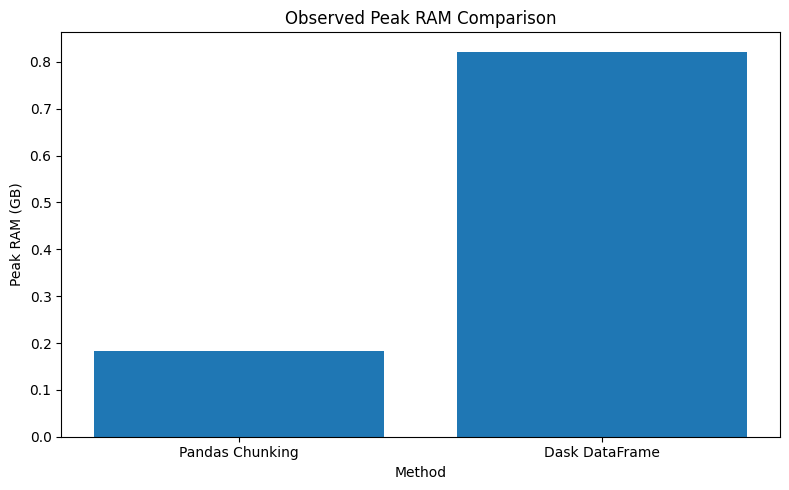

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Results recorded from the two experiments
results = pd.DataFrame({
    "Method": ["Pandas Chunking", "Dask DataFrame"],
    "Execution Time (seconds)": [261.22, 56.87],
    "RAM Before (GB)": [0.162, 0.228],
    "RAM After (GB)": [0.169, 0.259],
    "Peak RAM (GB)": [0.182, 0.822],
    "Peak Increase (GB)": [0.020, 0.593],
    "Global Mean": [29.4854, 29.4854],
    "Partitions / Chunks": [168, 147]
})

print("Performance Comparison")
display(results)

# Calculate speed improvement
pandas_time = 261.22
dask_time = 56.87

speedup = pandas_time / dask_time
time_reduction = (pandas_time - dask_time) / pandas_time * 100

print(f"\nDask speedup: {speedup:.2f}x")
print(f"Execution time reduction: {time_reduction:.2f}%")

# Plot execution time
plt.figure(figsize=(8, 5))
plt.bar(
    results["Method"],
    results["Execution Time (seconds)"]
)
plt.title("Execution Time Comparison")
plt.ylabel("Execution Time (seconds)")
plt.xlabel("Method")
plt.tight_layout()
plt.show()

# Plot observed peak RAM
plt.figure(figsize=(8, 5))
plt.bar(
    results["Method"],
    results["Peak RAM (GB)"]
)
plt.title("Observed Peak RAM Comparison")
plt.ylabel("Peak RAM (GB)")
plt.xlabel("Method")
plt.tight_layout()
plt.show()


# TP02: How to Work with Big Data Files (+5GB)

## 1. Introduction

Working with big data files can be challenging because loading an entire dataset into memory may require a large amount of RAM and processing time. This practical work explores different approaches for processing large CSV files using Python.

The main objectives are:

- To test traditional Pandas loading on a CSV file larger than 5 GB.
- To process the dataset using Pandas Chunking.
- To process the dataset using Dask DataFrame.
- To compare execution time and memory consumption.
- To identify an appropriate approach for working with large datasets.

## 2. Dataset Description and Environment

### 2.1 Dataset Description

The dataset used in this practical work is **Clash Royale S18 Ladder Datasets (37.9M matches)**, available on Kaggle.

Dataset link: https://www.kaggle.com/datasets/bwandowando/clash-royale-season-18-dec-0320-dataset

The selected CSV file is:

`battlesStaging_12072020_to_12262020_WL_tagged.csv`

Its approximate size is **9.20 GB**, making it suitable for testing techniques for processing large files.

The analysis focuses on the `winner.trophyChange` column, which represents the trophy change associated with the winner.

### 2.2 Environment and Tools

The experiments were conducted in a Kaggle Notebook environment using Python.

The main libraries used were:

- **Pandas:** for loading and processing tabular data.
- **Dask DataFrame:** for parallel and partitioned data processing.
- **psutil:** for monitoring the Python process's memory usage.
- **time:** for measuring execution time.

The file was accessed directly from the Kaggle input directory without uploading the large CSV file again.

## 3. Task 1: Traditional Pandas Loading

### 3.1 Methodology

The first experiment attempted to load the entire CSV file into a Pandas DataFrame using `pd.read_csv()`.

The purpose was to evaluate whether the traditional approach could process the selected 9.20 GB file in the available environment.

### 3.2 Results

The attempt to load the complete file did not finish successfully. However, no explicit `MemoryError` exception was recorded in the available results. Therefore, it is not possible to confirm that the failure was caused specifically by insufficient memory.

### 3.3 Discussion

Traditional Pandas loading attempts to construct a DataFrame from the CSV file in a single operation. This approach can require substantial memory because the in-memory representation may be larger than the original CSV file.

For a file of approximately 9.20 GB, this method can be inefficient or may fail depending on the available resources and the data's memory requirements.

The result motivated the use of alternative methods that process the data in smaller portions or partitions.

## 4. Task 2: Pandas Chunking

### 4.1 Methodology

Pandas Chunking processes a large CSV file in smaller portions instead of loading the entire file at once.

The experiment used a chunk size of **100,000 rows**. Each chunk was processed separately, and the valid values in `winner.trophyChange` were aggregated incrementally.

The total sum and number of valid values were accumulated to calculate the global mean:

\[
\text{Mean}=\frac{\text{Total Sum}}{\text{Number of Valid Values}}
\]

Execution time and process memory usage were monitored during the experiment.

### 4.2 Results

| Metric | Result |
|---|---:|
| Chunk size | 100,000 rows |
| Number of chunks | 168 |
| Total valid values | 16,795,959 |
| Total sum | 495,236,165 |
| Mean trophy change | 29.4854 |
| Execution time | 261.22 seconds |
| RAM before processing | 0.162 GB |
| RAM after processing | 0.169 GB |
| Observed peak process RAM | 0.182 GB |
| Peak RAM increase | 0.020 GB |

*Note: Peak RAM was estimated by periodically sampling the Python process's memory usage. The observed peak is an approximation and may miss short-lived memory spikes.*

### 4.3 Discussion

Pandas Chunking successfully processed the dataset by dividing it into smaller portions. Instead of keeping the entire CSV file in a single DataFrame, the program processed each chunk and updated the aggregate values.

The calculated mean was **29.4854**, based on 16,795,959 valid values.

The observed peak process memory was approximately 0.182 GB. This relatively low measured value demonstrates the memory efficiency of incremental processing in this experiment.

However, the method required 261.22 seconds to complete. Although it is straightforward and memory-efficient, processing chunks sequentially can take longer than a parallel processing approach.

## 5. Task 3: Dask DataFrame

### 5.1 Methodology

Dask DataFrame was used to process the same CSV file through partitions. The experiment selected only the `winner.trophyChange` column and used a block size of 64 MiB.

Dask supports **lazy evaluation**, which means that many operations are defined first and executed when a result is explicitly requested. In this experiment, the computation was triggered by calling `.compute()` on the mean calculation.

Dask divided the file into partitions and processed them through its task execution system. This approach can improve performance by allowing work to be performed on separate portions of the dataset.

### 5.2 Results

| Metric | Result |
|---|---:|
| Selected column | `winner.trophyChange` |
| Block size | 64 MiB |
| Number of partitions | 147 |
| Mean trophy change | 29.4854 |
| Execution time | 56.87 seconds |
| RAM before processing | 0.228 GB |
| RAM after processing | 0.259 GB |
| Observed peak process RAM | 0.822 GB |
| Peak RAM increase | 0.593 GB |

*Note: Memory figures represent approximate process RAM measurements obtained by periodic sampling.*

### 5.3 Discussion

Dask successfully processed the selected column and calculated the same mean as the Pandas Chunking experiment: **29.4854**.

The execution time was 56.87 seconds, considerably shorter than the 261.22 seconds recorded for Pandas Chunking.

However, Dask had a higher observed peak process memory usage of approximately 0.822 GB. This can be associated with partition processing, task scheduling, intermediate data, and parallel execution overhead.

The results illustrate a trade-off between execution speed and observed memory consumption. Dask was faster in this experiment, while Pandas Chunking used less peak process memory.

## 6. Performance Comparison

The following table summarizes the results of the experiments. The figures correspond to the recorded benchmark runs presented in this report.

| Metric | Traditional Pandas | Pandas Chunking | Dask DataFrame |
|---|---|---|---|
| Processing approach | Entire file | Chunks of 100,000 rows | Partitions of 64 MiB |
| Completion | Did not complete | Successful | Successful |
| Number of chunks/partitions | — | 168 chunks | 147 partitions |
| Mean trophy change | Not obtained | 29.4854 | 29.4854 |
| Execution time | Not available | 261.22 s | 56.87 s |
| RAM before | Not available | 0.162 GB | 0.228 GB |
| RAM after | Not available | 0.169 GB | 0.259 GB |
| Observed peak process RAM | Not available | 0.182 GB | 0.822 GB |

### 6.1 Execution Time Analysis

Dask completed the computation in 56.87 seconds, compared with 261.22 seconds for Pandas Chunking.

The speedup was approximately:

\[
\text{Speedup}=\frac{261.22}{56.87}\approx 4.59
\]

The relative reduction in execution time was approximately:

\[
\frac{261.22-56.87}{261.22}\times100
\approx78.2\%
\]

Therefore, Dask was approximately **4.59 times faster** than Pandas Chunking in the recorded experiments.

### 6.2 Memory Usage Analysis

Pandas Chunking had an observed peak process RAM of approximately 0.182 GB, while Dask reached approximately 0.822 GB.

This indicates that Dask used more peak process memory in these particular runs. The additional memory usage may be a trade-off for its partition-based execution and task management.

The measurements describe the observed Python process memory, not total system-wide memory. Because memory was sampled periodically, the recorded peak values are approximate.

### 6.3 Overall Comparison

Traditional Pandas loading did not complete, so no execution time or comparable memory result was obtained for that experiment.

Both Pandas Chunking and Dask completed the selected calculation and returned the same mean. Pandas Chunking was more memory-efficient according to the observed peak process RAM, whereas Dask achieved substantially shorter execution time.

The results apply to the tested file, selected column, software environment, and recorded runs. Execution times and memory consumption may vary under different conditions.

## 7. Conclusion

This practical work compared three approaches for processing a large CSV file of approximately 9.20 GB.

The traditional Pandas loading attempt did not complete, demonstrating the potential limitations of loading a large dataset in one operation. However, the available results do not establish that a `MemoryError` was the cause.

Pandas Chunking successfully processed the data in 168 chunks and calculated a mean trophy change of 29.4854. Its observed peak process memory was approximately 0.182 GB, although the computation took 261.22 seconds.

Dask DataFrame also calculated the same mean, using 147 partitions. It completed the computation in 56.87 seconds, approximately 4.59 times faster than Pandas Chunking, but its observed peak process memory was higher at approximately 0.822 GB.

In conclusion, **Pandas Chunking is a practical choice when minimizing observed memory usage is important, while Dask is a strong choice when faster processing is a priority and additional memory is available**. The appropriate method depends on the dataset size, computational resources, and performance requirements.
